# Semantic Segmentation on PASCAL VOC 2012

**Architecture:** Configurable: DeepLabV3+ or UNet++ with chosen encoder  
**Dataset:** PASCAL VOC 2012 (21 classes, segmentation split)  
**Library:** [`segmentation-models-pytorch`](https://github.com/qubvel/segmentation_models.pytorch)

---

In [1]:
!nvidia-smi

Fri Apr 17 01:40:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             35W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip install -q segmentation-models-pytorch

Note: you may need to restart the kernel to use updated packages.


## 1. Imports

In [3]:
import copy
import random
from pathlib import Path
from typing import Literal

import albumentations as A
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import segmentation_models_pytorch as smp
from albumentations.pytorch import ToTensorV2
from PIL import Image
from scipy.ndimage import distance_transform_edt
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

## 2. Configuration

In [4]:
# DATA_ROOT       = Path("VOC2012_train_val")# Paths
DATA_ROOT       = Path("../input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val")
CHECKPOINT_LAST = Path("last_model.pth")
CHECKPOINT_BEST = Path("best_model.pth")

# Model
ARCHITECTURE: Literal["deeplabv3plus", "unetplusplus", "segformer", "upernet"] = "segformer"
# ['resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152', 'resnext50_32x4d', 'resnext101_32x4d', 'resnext101_32x8d', 'resnext101_32x16d', 'resnext101_32x32d', 'resnext101_32x48d', 'dpn68', 'dpn68b', 'dpn92', 'dpn98', 'dpn107', 'dpn131', 'vgg11', 'vgg11_bn', 'vgg13', 'vgg13_bn', 'vgg16', 'vgg16_bn', 'vgg19', 'vgg19_bn', 'senet154', 'se_resnet50', 'se_resnet101', 'se_resnet152', 'se_resnext50_32x4d', 'se_resnext101_32x4d', 'densenet121', 'densenet169', 'densenet201', 'densenet161', 'inceptionresnetv2', 'inceptionv4', 'efficientnet-b0', 'efficientnet-b1', 'efficientnet-b2', 'efficientnet-b3', 'efficientnet-b4', 'efficientnet-b5', 'efficientnet-b6', 'efficientnet-b7', 'mobilenet_v2', 'xception', 'timm-efficientnet-b0', 'timm-efficientnet-b1', 'timm-efficientnet-b2', 'timm-efficientnet-b3', 'timm-efficientnet-b4', 'timm-efficientnet-b5', 'timm-efficientnet-b6', 'timm-efficientnet-b7', 'timm-efficientnet-b8', 'timm-efficientnet-l2', 'timm-tf_efficientnet_lite0', 'timm-tf_efficientnet_lite1', 'timm-tf_efficientnet_lite2', 'timm-tf_efficientnet_lite3', 'timm-tf_efficientnet_lite4', 'timm-skresnet18', 'timm-skresnet34', 'timm-skresnext50_32x4d', 'mit_b0', 'mit_b1', 'mit_b2', 'mit_b3', 'mit_b4', 'mit_b5', 'mobileone_s0', 'mobileone_s1', 'mobileone_s2', 'mobileone_s3', 'mobileone_s4']"

ENCODER         = "mit_b2"  # for SegFormer use mit_b0..mit_b5
ENCODER_WEIGHTS = "imagenet"   # pretrained backbone weights
OUTPUT_STRIDE   = 16            # used only by DeepLabV3+

USE_DATA_PARALLEL = False

# Training
IMAGE_SIZE              = 256
BATCH_SIZE              = 32
NUM_WORKERS             = 2
LEARNING_RATE           = 1e-4
WEIGHT_DECAY            = 1e-4
NUM_EPOCHS              = 50
EARLY_STOPPING_PATIENCE = 5
IGNORE_INDEX            = 255  # VOC boundary/void pixels

# LR Scheduler (ReduceLROnPlateau on validation loss)
SCHEDULER_FACTOR        = 0.5
SCHEDULER_PATIENCE      = 2
SCHEDULER_MIN_LR        = 1e-6

# Device
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"Data   : {DATA_ROOT.resolve()}")
print(f"Arch   : {ARCHITECTURE}")

gpu_count = torch.cuda.device_count()
print(f"GPU count: {gpu_count}")
for i in range(gpu_count):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

Device : cuda:0
Data   : /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val
Arch   : segformer
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. PASCAL VOC 2012 Dataset

In [5]:
VOC_CLASSES = [
    "background",
    "aeroplane",
    "bicycle",
    "bird",
    "boat",
    "bottle",
    "bus",
    "car",
    "cat",
    "chair",
    "cow",
    "diningtable",
    "dog",
    "horse",
    "motorbike",
    "person",
    "potted plant",
    "sheep",
    "sofa",
    "train",
    "tv/monitor",
]


VOC_COLORMAP = np.array([
    [0, 0, 0],
    [128, 0, 0],
    [0, 128, 0],
    [128, 128, 0],
    [0, 0, 128],
    [128, 0, 128],
    [0, 128, 128],
    [128, 128, 128],
    [64, 0, 0],
    [192, 0, 0],
    [64, 128, 0],
    [192, 128, 0],
    [64, 0, 128],
    [192, 0, 128],
    [64, 128, 128],
    [192, 128, 128],
    [0, 64, 0],
    [128, 64, 0],
    [0, 192, 0],
    [128, 192, 0],
    [0, 64, 128],
], dtype=np.uint8)

NUM_CLASSES = len(VOC_CLASSES)  # 21
print(f"Number of classes : {NUM_CLASSES}")

Number of classes : 21


In [6]:
def decode_segmentation_mask(mask: np.ndarray) -> np.ndarray:
    """Map class-index mask (H, W) → RGB image (H, W, 3) for display."""
    h, w = mask.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for cls_idx, color in enumerate(VOC_COLORMAP):
        rgb[mask == cls_idx] = color
    return rgb


class PascalVOCDataset(Dataset):
    """
    PASCAL VOC 2012 Segmentation dataset.

    Expected directory layout (standard VOC structure):
        <root>/
            ImageSets/Segmentation/{train,val}.txt
            JPEGImages/<id>.jpg
            SegmentationClass/<id>.png   ← palette PNG; pixel value = class index
    """

    def __init__(self, root: Path, split: str = "train", transform: A.Compose | None = None):
        assert split in {
            "train", "val"}, f"split must be 'train' or 'val', got '{split}'"
        split_file = root / "ImageSets" / "Segmentation" / f"{split}.txt"
        self.ids = split_file.read_text().strip().splitlines()
        self.root = root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, idx: int):
        name = self.ids[idx]
        image = cv2.imread(str(self.root / "JPEGImages" / f"{name}.jpg"))
        
        if image is None:
            raise FileNotFoundError(f"Image file not found: {self.root / 'JPEGImages' / f'{name}.jpg'}")
        
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB,
        )
        # palette PNG stores the class index directly as the pixel value (0-20, 255=boundary)
        mask = np.array(Image.open(
            self.root / "SegmentationClass" / f"{name}.png"))

        if self.transform is not None:
            out = self.transform(image=image, mask=mask)
            image = out["image"]
            mask = out["mask"]

        mask_tensor: torch.Tensor = mask if isinstance(mask, torch.Tensor) else torch.from_numpy(mask)
        return image, mask_tensor.long()

## 4. Data Transforms & Loaders

In [7]:
# ImageNet statistics match the pretrained encoder weights
_IMAGENET_MEAN = (0.485, 0.456, 0.406)
_IMAGENET_STD  = (0.229, 0.224, 0.225)

train_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.05,
        rotate_limit=15,
        border_mode=cv2.BORDER_CONSTANT,
        p=0.5,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.3),
    A.GaussNoise(p=0.05),
    A.Normalize(mean=_IMAGENET_MEAN, std=_IMAGENET_STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=_IMAGENET_MEAN, std=_IMAGENET_STD),
    ToTensorV2(),
])

train_dataset = PascalVOCDataset(DATA_ROOT, split="train", transform=train_transform)
val_dataset   = PascalVOCDataset(DATA_ROOT, split="val",   transform=val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
)


print(f"Train samples : {len(train_dataset)}")
print(f"Val   samples : {len(val_dataset)}")

Train samples : 1464
Val   samples : 1449


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## 5. Model

Using [`segmentation-models-pytorch`](https://github.com/qubvel/segmentation_models.pytorch).
`ARCHITECTURE` can be `"deeplabv3plus"`, `"unetplusplus"`, `"segformer"`, or `"upernet"`.
For SegFormer, use `ENCODER` from `mit_b0` to `mit_b5`.

In [8]:
def build_model(architecture: str) -> nn.Module:
    arch = architecture.lower()
    if arch in {"deeplabv3plus", "deeplabv3+"}:
        return smp.DeepLabV3Plus(
            encoder_name=ENCODER,
            encoder_weights=ENCODER_WEIGHTS,
            in_channels=3,
            classes=NUM_CLASSES,
            encoder_output_stride=OUTPUT_STRIDE,
        )
    if arch in {"unetplusplus", "unet++"}:
        return smp.UnetPlusPlus(
            encoder_name=ENCODER,
            encoder_weights=ENCODER_WEIGHTS,
            in_channels=3,
            classes=NUM_CLASSES,
        )
    if arch == "segformer":
        if not ENCODER.startswith("mit_b"):
            raise ValueError("SegFormer requires ENCODER in {'mit_b0','mit_b1','mit_b2','mit_b3','mit_b4','mit_b5'}.")
        return smp.Segformer(
            encoder_name=ENCODER,
            encoder_weights=ENCODER_WEIGHTS,
            in_channels=3,
            classes=NUM_CLASSES,
        )
    if arch == "upernet":
        return smp.UPerNet(
            encoder_name=ENCODER,
            encoder_weights=ENCODER_WEIGHTS,
            in_channels=3,
            classes=NUM_CLASSES,
        )
    raise ValueError(
        "Unsupported ARCHITECTURE. Use one of: 'deeplabv3plus', 'unetplusplus', 'segformer', 'upernet'."
    )


model = build_model(ARCHITECTURE)

if USE_DATA_PARALLEL and torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs with DataParallel")
    model = nn.DataParallel(model)

model = model.to(DEVICE)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=SCHEDULER_MIN_LR,
)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

print(f"Model  : {ARCHITECTURE} / {ENCODER}")
try:
    encoder = model.module.encoder
    decoder = model.module.decoder
except AttributeError:
    encoder = model.encoder
    decoder = model.decoder

    
n_params_encoder = sum(p.numel() for p in encoder.parameters() if p.requires_grad)
n_params_decoder = sum(p.numel() for p in decoder.parameters() if p.requires_grad)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Params : {n_params:,}")
print(f"Encoder : {n_params_encoder:,} ({n_params_encoder / n_params:.1%})")
print(f"Decoder : {n_params_decoder:,} ({n_params_decoder / n_params:.1%})")

Model  : segformer / mit_b2
Params : 24,727,509
Encoder : 24,196,288 (97.9%)
Decoder : 525,824 (2.1%)


## 6. Training Utilities

In [9]:
class EarlyStopping:
    """Stop training when validation loss stops improving."""

    def __init__(self, patience: int = 10, min_delta: float = 0.0, restore_best: bool = False):
        self.patience     = patience
        self.min_delta    = min_delta
        self.restore_best = restore_best
        self.best_weights = None
        self.best_loss    = float("inf")
        self.counter      = 0

    def step(self, model: nn.Module, val_loss: float) -> bool:
        """Returns True when training should stop."""
        if self.best_loss - val_loss > self.min_delta:
            self.best_loss    = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.counter      = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                if self.restore_best and self.best_weights is not None:
                    model.load_state_dict(self.best_weights)
                return True
        return False

    def __repr__(self) -> str:
        return f"EarlyStopping(patience={self.patience}, counter={self.counter}/{self.patience})"


def get_state_dict_for_save(model: nn.Module) -> dict:
    if isinstance(model, nn.DataParallel):
        return model.module.state_dict()
    return model.state_dict()


def save_checkpoint(model: nn.Module, epoch: int, loss: float, path: Path) -> None:
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": get_state_dict_for_save(model),
            "loss": loss,
        },
        path,
    )


def load_checkpoint(model: nn.Module, checkpoint_path: Path, device: torch.device) -> dict:
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    state_dict = checkpoint["model_state_dict"]

    if isinstance(model, nn.DataParallel):
        model.module.load_state_dict(state_dict)
    else:
        if any(key.startswith("module.") for key in state_dict):
            state_dict = {key.replace("module.", "", 1): value for key, value in state_dict.items()}
        model.load_state_dict(state_dict)

    return checkpoint


def compute_segmentation_metrics_from_counts(tp: torch.Tensor, fp: torch.Tensor, fn: torch.Tensor) -> dict:
    union = tp + fp + fn
    iou_per_class = (tp / union.clamp(min=1)).numpy()
    dice_per_class = (2 * tp / (2 * tp + fp + fn).clamp(min=1)).numpy()

    present = union.numpy() > 0
    miou = float(iou_per_class[present].mean()) if present.any() else float("nan")
    mdice = float(dice_per_class[present].mean()) if present.any() else float("nan")

    return {
        "miou": miou,
        "dice": mdice,
        "iou_per_class": iou_per_class,
        "dice_per_class": dice_per_class,
    }


def _hausdorff_binary(pred: np.ndarray, gt: np.ndarray) -> float:
    """
    Symmetric Hausdorff distance between two binary masks, computed via EDT.

    Returns 0.0 when both masks are empty (class absent in this image).
    Returns NaN when only one mask is empty - callers should skip these.
    """
    if not pred.any() and not gt.any():
        return 0.0
    if not pred.any() or not gt.any():
        return np.nan

    dist_pred = distance_transform_edt(~pred)
    dist_gt   = distance_transform_edt(~gt)
    if dist_gt is None or dist_pred is None:
        return np.nan
    
    return float(max(dist_gt[pred].max(), dist_pred[gt].max()))


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    num_classes: int,
    device: torch.device,
    ignore_index: int = 255,
    hausdorff: bool = True,
) -> dict:
    """
    Run the model over a data split and return segmentation metrics.

    Metrics:
        miou            mean IoU across classes present in the ground truth
        dice            mean Dice coefficient
        hausdorff       mean Hausdorff distance in pixels (None if hausdorff=False)
        iou_per_class   per-class IoU array  (length = num_classes)
        dice_per_class  per-class Dice array (length = num_classes)

    IoU and Dice are computed globally by accumulating TP/FP/FN over the full split,
    which is more stable than averaging per-image values.

    Hausdorff is inherently per-image (it is not additive), so it is computed per
    image per class and then averaged. Setting hausdorff=False skips this and saves
    a significant amount of time on large validation sets.

    Boundary/void pixels (ignore_index=255) are excluded from all metrics.
    """
    model.eval()

    tp = torch.zeros(num_classes)
    fp = torch.zeros(num_classes)
    fn = torch.zeros(num_classes)
    hd_per_class: list[list[float]] = [[] for _ in range(num_classes)]

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Evaluating", leave=False):
            preds = model(images.to(device)).argmax(dim=1).cpu()
            valid = masks != ignore_index

            for cls in range(num_classes):
                pred_cls   = (preds == cls) & valid
                target_cls = (masks == cls) & valid
                tp[cls] += (pred_cls & target_cls).sum()
                fp[cls] += (pred_cls & ~target_cls).sum()
                fn[cls] += (~pred_cls & target_cls).sum()

            if hausdorff:
                for b in range(preds.shape[0]):
                    v = valid[b].numpy()
                    p = preds[b].numpy()
                    m = masks[b].numpy()
                    for cls in range(num_classes):
                        hd = _hausdorff_binary((p == cls) & v, (m == cls) & v)
                        if not np.isnan(hd):
                            hd_per_class[cls].append(hd)

    metrics = compute_segmentation_metrics_from_counts(tp, fp, fn)
    mean_hd = None
    if hausdorff:
        class_means = [np.mean(v) for v in hd_per_class if v]
        mean_hd = float(np.mean(class_means)) if class_means else np.nan

    metrics["hausdorff"] = mean_hd
    return metrics

## 7. Training Loop

In [10]:
@torch.no_grad()
def update_confmat(confmat, preds, masks, num_classes, ignore_index):
    valid = masks != ignore_index
    labels = masks[valid]
    preds = preds[valid]
    idx = labels * num_classes + preds
    confmat += torch.bincount(
        idx,
        minlength=num_classes * num_classes,
    ).reshape(num_classes, num_classes)

In [11]:
def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: optim.lr_scheduler.ReduceLROnPlateau | None,
    num_epochs: int,
    device: torch.device,
    early_stopping: EarlyStopping,
) -> None:
    best_val_loss = float("inf")

    for epoch in range(1, num_epochs + 1):
        # train step
        model.train()
        train_loss = 0.0
        bar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [train]", colour="cyan")
        for images, masks in bar:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            bar.set_postfix(loss=f"{loss.item():.4f}")

        avg_train_loss = train_loss / len(train_loader)

        # validation step
        model.eval()
        val_loss = 0.0
        confmat = torch.zeros(NUM_CLASSES, NUM_CLASSES, device=device)

        with torch.inference_mode():
            for images, masks in val_loader:
                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)

                logits = model(images)
                val_loss += criterion(logits, masks).item()

                preds = logits.argmax(dim=1)
                update_confmat(confmat, preds, masks, NUM_CLASSES, IGNORE_INDEX)

        tp = confmat.diag()
        fp = confmat.sum(dim=0) - tp
        fn = confmat.sum(dim=1) - tp
        val_metrics = compute_segmentation_metrics_from_counts(
            tp.cpu(),
            fp.cpu(),
            fn.cpu(),
        )

        avg_val_loss = val_loss / len(val_loader)

        if scheduler is not None:
            scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch:>3}/{num_epochs}]  "
            f"train_loss={avg_train_loss:.4f}  val_loss={avg_val_loss:.4f}  "
            f"val_mIoU={val_metrics['miou']:.4f}  val_Dice={val_metrics['dice']:.4f}  "
            f"lr={current_lr:.2e}  {early_stopping}"
        )

        # checkpointing
        save_checkpoint(model, epoch, avg_val_loss, CHECKPOINT_LAST)
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            save_checkpoint(model, epoch, avg_val_loss, CHECKPOINT_BEST)
            print(f"New best val_loss={best_val_loss:.4f} — checkpoint saved")

        if early_stopping.step(model, avg_val_loss):
            print(f"Early stopping triggered at epoch {epoch}.")
            break

In [12]:
early_stopping = EarlyStopping(patience=EARLY_STOPPING_PATIENCE, restore_best=True)

train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=NUM_EPOCHS,
    device=DEVICE,
    early_stopping=early_stopping,
)

Epoch 1/50 [train]: 100%|██████████| 46/46 [00:59<00:00,  1.30s/it, loss=1.1853]


Epoch [  1/50]  train_loss=1.6718  val_loss=0.9187  val_mIoU=0.4425  val_Dice=0.5829  lr=1.00e-04  EarlyStopping(patience=5, counter=0/5)
New best val_loss=0.9187 — checkpoint saved


Epoch 2/50 [train]: 100%|██████████| 46/46 [00:53<00:00,  1.17s/it, loss=0.4699]


Epoch [  2/50]  train_loss=0.7228  val_loss=0.5829  val_mIoU=0.5689  val_Dice=0.6997  lr=1.00e-04  EarlyStopping(patience=5, counter=0/5)
New best val_loss=0.5829 — checkpoint saved


Epoch 3/50 [train]: 100%|██████████| 46/46 [00:52<00:00,  1.15s/it, loss=0.3647]


...

Epoch [ 25/50]  train_loss=0.1003  val_loss=0.2683  val_mIoU=0.7274  val_Dice=0.8312  lr=1.25e-05  EarlyStopping(patience=5, counter=2/5)


Epoch 26/50 [train]: 100%|██████████| 46/46 [00:52<00:00,  1.14s/it, loss=0.0617]


Epoch [ 26/50]  train_loss=0.0978  val_loss=0.2560  val_mIoU=0.7283  val_Dice=0.8322  lr=1.25e-05  EarlyStopping(patience=5, counter=3/5)


Epoch 27/50 [train]: 100%|██████████| 46/46 [00:52<00:00,  1.14s/it, loss=0.1024]


Epoch [ 27/50]  train_loss=0.0961  val_loss=0.2579  val_mIoU=0.7238  val_Dice=0.8286  lr=1.25e-05  EarlyStopping(patience=5, counter=4/5)
Early stopping triggered at epoch 27.


## 8. Evaluation

In [13]:
checkpoint = load_checkpoint(model, CHECKPOINT_BEST, DEVICE)
print(f"Loaded checkpoint from epoch {checkpoint['epoch']}  (val_loss={checkpoint['loss']:.4f})\n")

# hausdorff=True is slow; set to False to skip it
metrics = evaluate(model, val_loader, NUM_CLASSES, DEVICE, ignore_index=IGNORE_INDEX, hausdorff=True)

print(f"mIoU      : {metrics['miou']:.4f}  ({metrics['miou'] * 100:.2f}%)")
print(f"Dice      : {metrics['dice']:.4f}  ({metrics['dice'] * 100:.2f}%)")
if metrics["hausdorff"] is not None:
    print(f"Hausdorff : {metrics['hausdorff']:.2f} px (mean over classes)")

Loaded checkpoint from epoch 22  (val_loss=0.2559)



mIoU      : 0.7263  (72.63%)
Dice      : 0.8303  (83.03%)
Hausdorff : 4.19 px (mean over classes)


Comparison table:

| Model                                       | val_loss   | mIoU       | Dice       | Haussdorf (px) |
| ------------------------------------------- | ---------- | ---------- | ---------- | -------------- |
| DeepLabV3+ ResNet-101                       | 0.3440     | 0.6413     | ???        | ???            |
| DeepLabV3+ ResNet-101 prevented overfitting | 0.3784     | 0.5945     | 0.7277     | 4.93           |
| DeepLabV3+ ResNet-50                        | 0.3840     | 0.5417     | 0.6840     | 5.03           |
| DeepLabV3+ ResNet-50 + scheduler            | 0.2958     | 0.6401     | 0.7661     | 4.82           |
| DeepLabV3+ EfficientNet-B0                  | 0.3296     | 0.6046     | 0.7367     | 4.92           |
| DeepLabV3+ SE-ResNeXt-101                   | 0.2614     | 0.6919     | 0.8058     | 4.61           |
| UNet++ whatever encoder                     | poor       | bad        | ugly       | 1000+          |
| SegFormer mit_b2                            | **0.2559** | **0.7263** | **0.8303** | **4.19**       |


## 9. Visualisation — Predictions vs Ground Truth

Displaying indices: [1437, 878, 1324, 314, 51, 574]


/tmp/ipykernel_974/1206063371.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  image_t = torch.tensor(image_t)


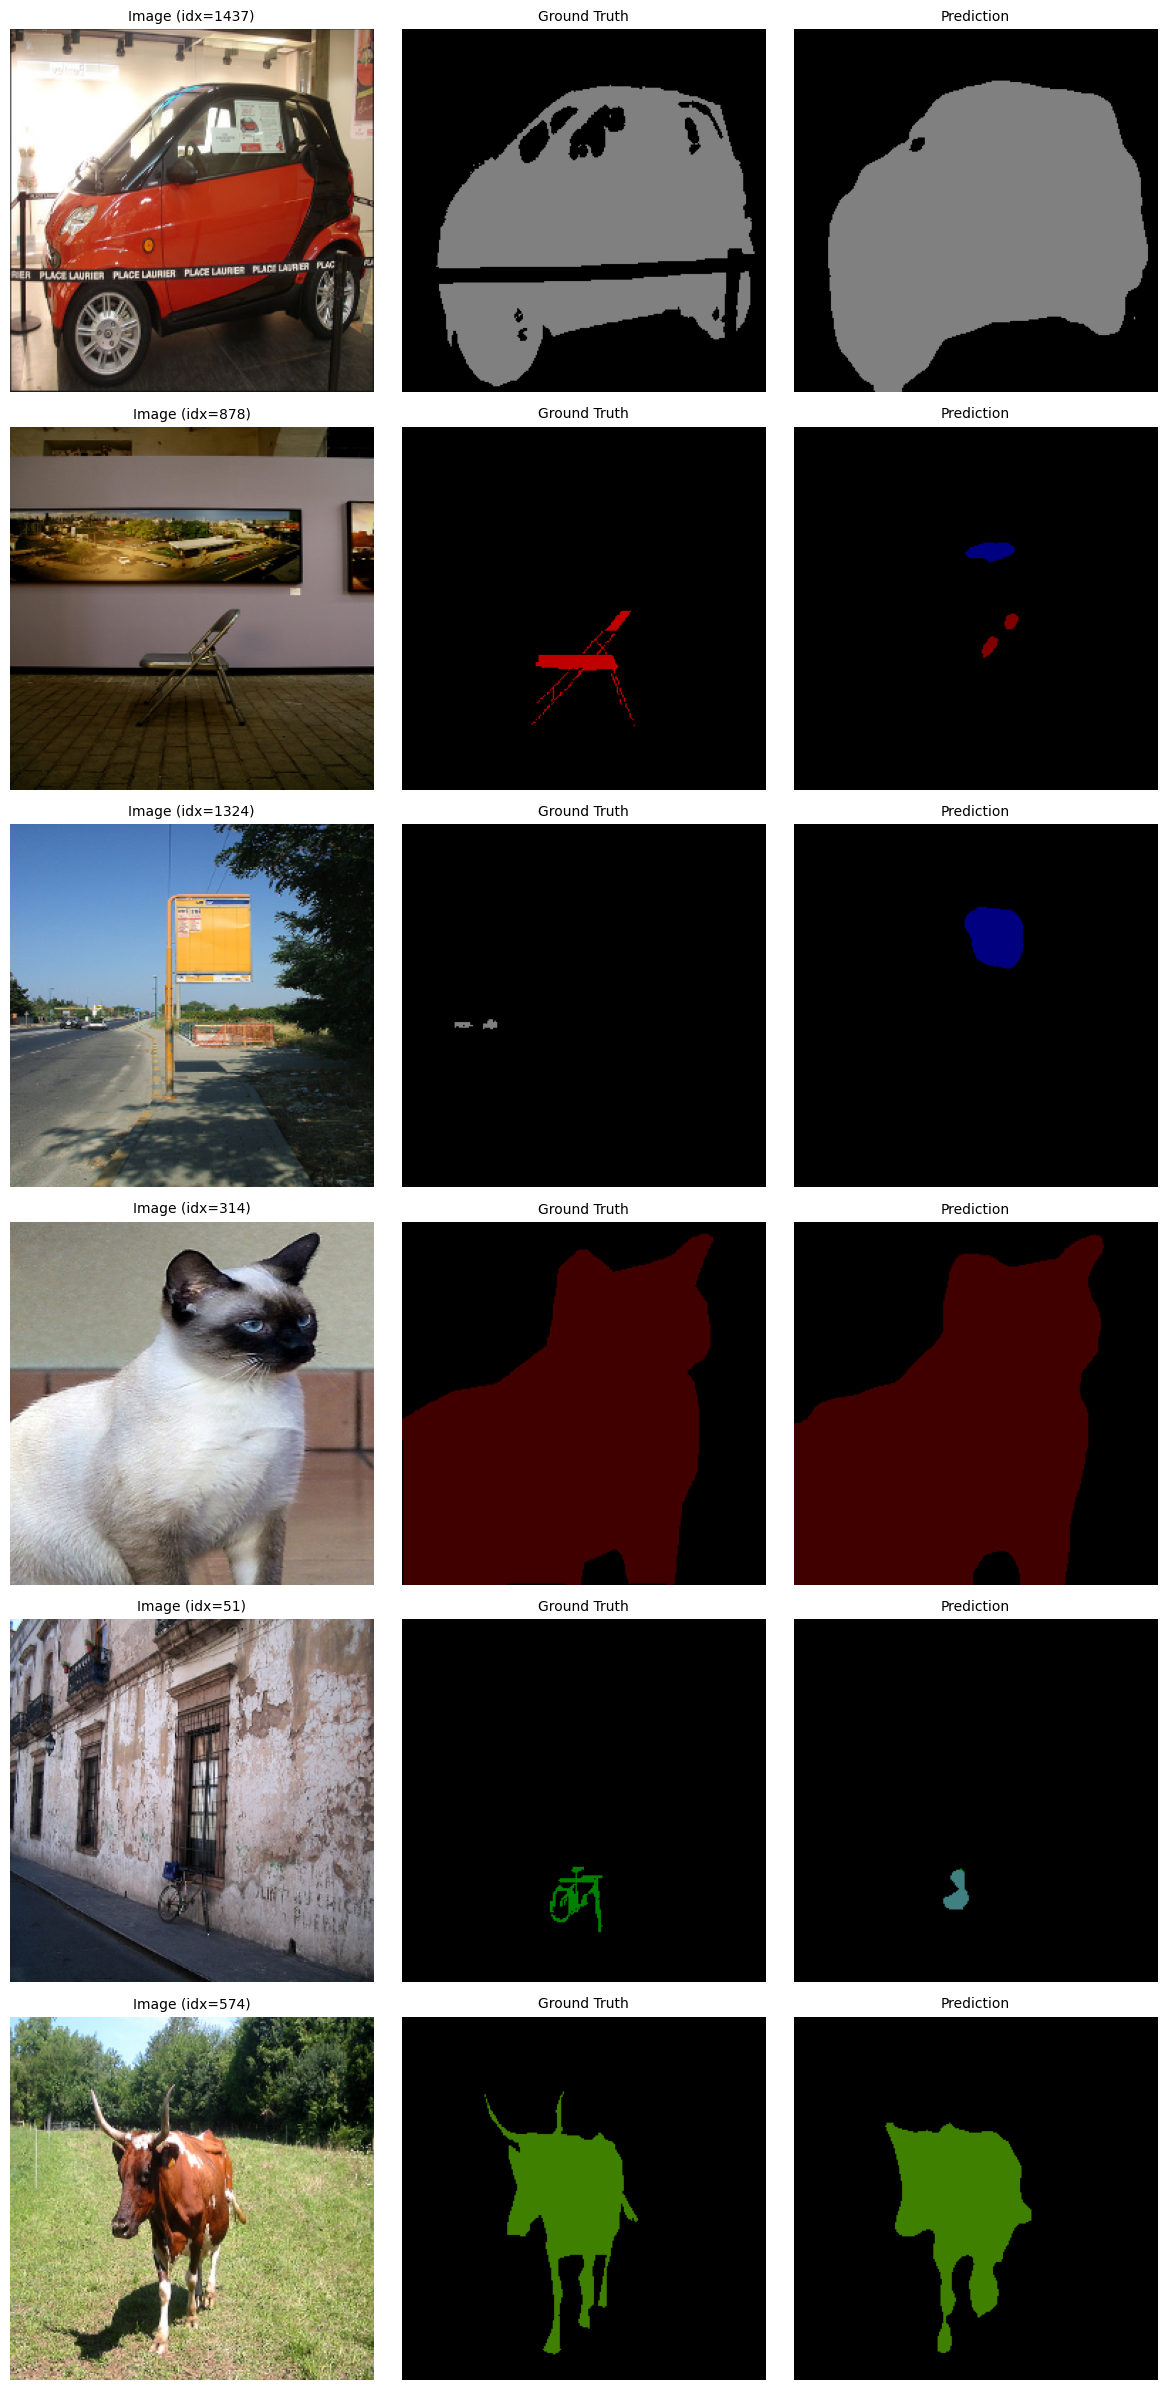

In [14]:
def visualize_predictions(
    model: nn.Module,
    dataset: PascalVOCDataset,
    device: torch.device,
    indices: list[int] | None = None,
    n_random: int = 6,
    imagenet_mean: tuple = (0.485, 0.456, 0.406),
    imagenet_std:  tuple = (0.229, 0.224, 0.225),
) -> None:
    """Display original image, ground-truth mask, and predicted mask side-by-side."""
    if indices is None:
        indices = random.sample(range(len(dataset)), min(n_random, len(dataset)))
    print(f"Displaying indices: {indices}")

    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std  = torch.tensor(imagenet_std).view(3, 1, 1)

    model.eval()
    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    if len(indices) == 1:
        axes = axes[np.newaxis, :]  # ensure 2-D indexing works for a single row

    with torch.no_grad():
        for row, idx in enumerate(indices):
            image_t, mask = dataset[idx]           # (C, H, W), (H, W)
            image_t = torch.tensor(image_t)
            pred = model(image_t.unsqueeze(0).to(device)).argmax(dim=1).squeeze().cpu().numpy()

            # Undo normalisation for display
            image_display = (image_t * std + mean).permute(1, 2, 0).numpy().clip(0, 1)
            gt_display    = decode_segmentation_mask(mask.numpy())
            pred_display  = decode_segmentation_mask(pred)

            for ax, img, title in zip(
                axes[row],
                [image_display, gt_display, pred_display],
                [f"Image (idx={idx})", "Ground Truth", "Prediction"],
            ):
                ax.imshow(img)
                ax.set_title(title, fontsize=10)
                ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, val_dataset, DEVICE, n_random=6)